In [17]:
from advanced_rag.retriever import get_mmr_retriever
from advanced_rag.models import get_groq

llm = get_groq()
retriever = get_mmr_retriever(lambda_mult=0.8)

In [18]:
from langchain_core.prompts import ChatPromptTemplate

prompt_template = ChatPromptTemplate(
    [
        (
            "system",
            """Answer the user's question using only the provided context.
If the answer is not present in the context, say you don't know.

Context:
{context}""",
        ),
        ("human", "{question}"),
    ]
)


In [19]:
final_chain = prompt_template | llm

In [20]:
from typing import TypedDict

In [21]:
class RagState(TypedDict):
    question: str
    context: str
    final_answer: str

In [22]:
def retrieve_document(state: RagState):
    user_query = state["question"]
    return {"context": retriever.invoke(user_query)}

In [23]:
def get_final_answer(state: RagState):
    final_answer = final_chain.invoke(
        {"context": state["context"], "question": state["question"]}
    )
    return {"final_answer": final_answer}

In [24]:
from langgraph.graph import StateGraph, START, END

In [25]:
graph = StateGraph(state_schema=RagState)

In [26]:
graph.add_node("retrieve_document", retrieve_document)
graph.add_node("get_final_answer", get_final_answer)

In [27]:
graph.add_edge(START, "retrieve_document")
graph.add_edge("retrieve_document", "get_final_answer")
graph.add_edge("get_final_answer", END)

In [28]:
workflow = graph.compile()

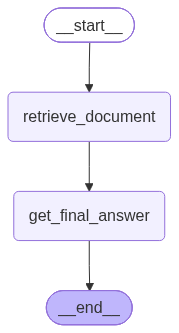

In [29]:
workflow

In [30]:
from rich import print

inital_state = {
    "question": "what are the government officials mentioned in these documents"
}
res = workflow.invoke(inital_state)

print(res["final_answer"].content)

**Government officials referenced in the two excerpts**

| # | Name | Title / Position | Department / Organization |
|---|------|------------------|---------------------------|
| 1 | Dr. **Rakesh Sarwal** | Additional Secretary, Chairman | Niti Aayog |
| 2 | Shri **Sunil Kumar** | Joint Secretary (R), Member Secretary | Ministry of Petroleum & Natural Gas |
| 3 | Shri **Amit Mehta** | Joint Secretary, Member | Department of Heavy Industries |
| 4 | Shri **Amit Varadan** | Joint Secretary, Member | Ministry of Road Transport & Highways |
| 5 | Shri **Subodh Kumar Singh** | Joint Secretary (Sugar), Member | Department of Food & Public Distribution |
| 6 | Dr. **S.S.V. Ramakumar** | Director (R&D), Member | Indian Oil Corporation Limited |
| 7 | Dr. **Reji Mathai** | Director, Member | Automotive Research Association of India (ARAI) |
| 8 | Shri **Niranjan Chandrashekhar Cheriyamane** | Deputy Secretary | Cabinet Secretariat, Rashtrapati Bhavan, 
New Delhi (copy‑to) |

*The “copy‑to” and “copy also to” lines on page 54 list personal secretaries to various ministers and secretaries, 
but the main government officials highlighted in the documents are those above.*